# On-Going 2 · Phân tích và dự đoán bệnh tim mạch

On-Going 1 đã tạo tệp `cleaned_cardio.csv`. Đặt tệp này cùng thư mục với notebook (trên Colab, tải vào mục **Files**), rồi chạy các ô từ trên xuống. Mỗi hàng là một người. Nhãn `cardio` bằng 0 nếu không có bệnh và bằng 1 nếu có bệnh.

Ta sẽ tìm những chỉ số khác nhau giữa hai nhóm, dùng chúng để dự đoán nhãn, rồi kiểm tra mô hình bỏ sót bao nhiêu trường hợp.

# Phần 1. Khám phá dữ liệu

#### 1.1. Đọc dữ liệu và xem phân bố

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập đường dẫn đến tệp dữ liệu đã làm sạch
data_path = "cleaned_cardio.csv"

# pd.read_csv() đọc tệp CSV và trả về một bảng dữ liệu (DataFrame)
cardio_data = pd.read_csv(data_path)

In [2]:
# Kiểm tra thông tin kích thước và xem qua dữ liệu

# .shape trả về (số hàng, số cột) của bảng dữ liệu
print("Kích thước dữ liệu:", cardio_data.shape)

# .columns.tolist() lấy tên các cột và chuyển thành list
column_names = cardio_data.columns.tolist()
print("Tên cột:", column_names)

# .head() lấy 5 hàng đầu tiên; display() hiển thị bảng đẹp hơn print() trong notebook
display(cardio_data.head())

Kích thước dữ liệu: (59162, 13)
Tên cột: ['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio']


,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,50,2,168,62.0,110,80,1,1,0,0,1,0
1,1,55,1,156,85.0,140,90,3,1,0,0,1,1
2,2,52,1,165,64.0,130,70,3,1,0,0,0,1
3,3,48,2,169,82.0,150,100,1,1,0,0,1,1
4,8,60,1,151,67.0,120,80,2,2,0,0,0,0


**Hai nhóm có bao nhiêu người?** Bảng cho biết tỷ lệ phần trăm, còn chiều cao của cột cho biết số người.


Tỷ lệ cardio (%):
cardio
0    48.98
1    51.02
Name: proportion, dtype: float64


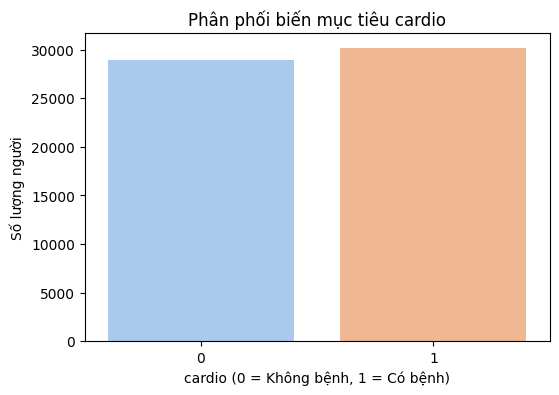

In [3]:
# Tỷ lệ phân phối của biến mục tiêu cardio
print("\nTỷ lệ cardio (%):")

# Bước 1: value_counts(normalize=True) đếm mỗi giá trị và trả về tỷ lệ (từ 0 đến 1)
cardio_percentage = cardio_data["cardio"].value_counts(normalize=True)

# Bước 2: sort_index() sắp xếp theo giá trị nhãn (0 trước, 1 sau)
cardio_percentage = cardio_percentage.sort_index()

# Bước 3: nhân 100 để đổi sang phần trăm
cardio_percentage = cardio_percentage * 100

# Bước 4: round(2) làm tròn 2 chữ số thập phân
cardio_percentage = cardio_percentage.round(2)

print(cardio_percentage)

# Trực quan hóa biến mục tiêu
# figsize=(6, 4): biểu đồ rộng 6 inch, cao 4 inch
plt.figure(figsize=(6, 4))

# sns.countplot() vẽ biểu đồ cột, mỗi cột là số người của một nhãn
sns.countplot(data=cardio_data, x="cardio", hue="cardio", palette="pastel", legend=False)
plt.title("Phân phối biến mục tiêu cardio")
plt.xlabel("cardio (0 = Không bệnh, 1 = Có bệnh)")
plt.ylabel("Số lượng người")
plt.show()

**Các chỉ số tập trung ở khoảng nào?** Mỗi cột trong histogram đếm số người thuộc một khoảng giá trị.

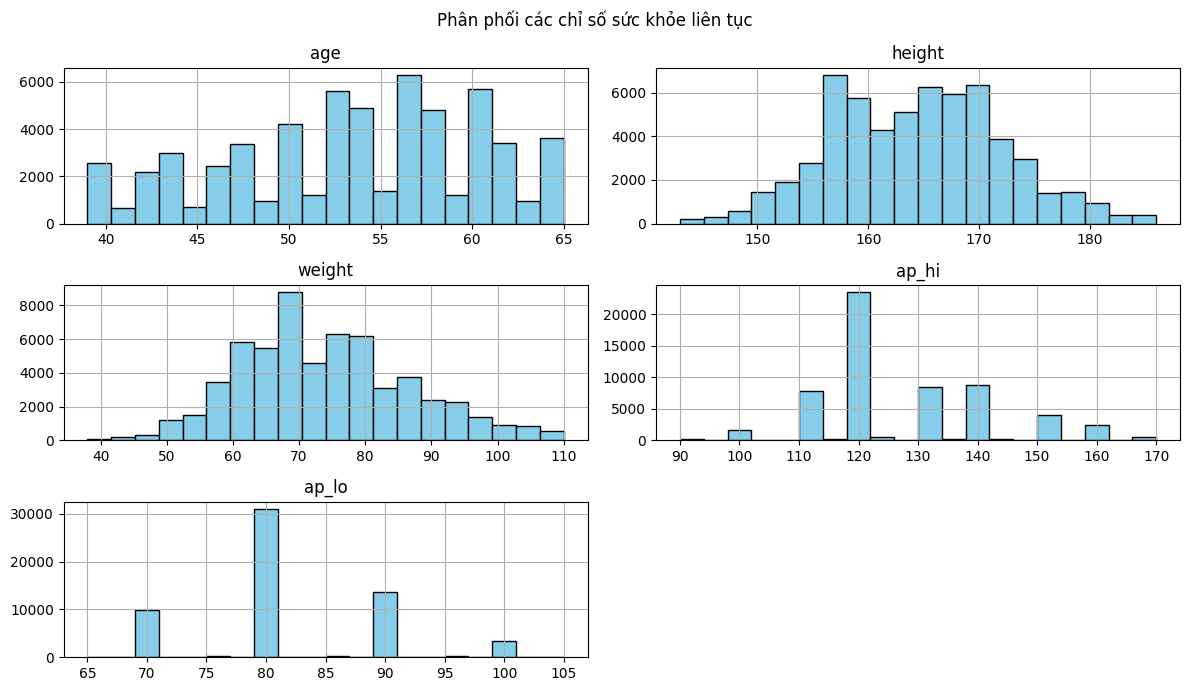

In [4]:
# Histogram phân phối các chỉ số thể chất và sức khỏe

# Danh sách các cột số liên tục cần vẽ
continuous_columns = ["age", "height", "weight", "ap_hi", "ap_lo"]

# Lấy riêng các cột cần vẽ ra một bảng nhỏ
continuous_data = cardio_data[continuous_columns]

# .hist() vẽ một histogram cho mỗi cột
# bins=20: chia dữ liệu thành 20 khoảng; edgecolor="black": viền đen cho mỗi cột
continuous_data.hist(figsize=(12, 7), bins=20, color="skyblue", edgecolor="black")

# suptitle() đặt tiêu đề chung cho cả hình
plt.suptitle("Phân phối các chỉ số sức khỏe liên tục")

# tight_layout() tự căn khoảng cách để các biểu đồ con không đè lên nhau
plt.tight_layout()
plt.show()

#### 1.2. So sánh người có bệnh và không có bệnh

Đường giữa mỗi hộp là trung vị. So sánh hai đường này để xem chỉ số nào thường cao hơn ở nhóm có bệnh.

In [ ]:
# Boxplot cho các biến liên tục phân theo nhóm cardio

# plt.subplots(2, 3) tạo một hình (figure) gồm 2 hàng x 3 cột = 6 ô biểu đồ (axis)
figure, axis_grid = plt.subplots(2, 3, figsize=(14, 8))

# .flatten() biến lưới 2 chiều thành danh sách 1 chiều để truy cập bằng 0, 1, 2, ...
axis_list = axis_grid.flatten()

numeric_columns = ["ap_hi", "age", "height", "weight", "ap_lo"]

# enumerate() trả về cùng lúc vị trí (0, 1, 2, ...) và giá trị trong danh sách
for position, column_name in enumerate(numeric_columns):
    current_axis = axis_list[position]

    # sns.boxplot() vẽ biểu đồ hộp: đường giữa hộp là trung vị
    sns.boxplot(data=cardio_data, x="cardio", y=column_name, hue="cardio", dodge=False, legend=False, ax=current_axis, palette="Set2")

    chart_title = "Phân phối " + column_name + " theo cardio"
    current_axis.set_title(chart_title)
    current_axis.set_xlabel("cardio")

# Chỉ có 5 cột nên xóa ô thứ 6 (vị trí 5) bị thừa
figure.delaxes(axis_list[5])
plt.tight_layout()
plt.show()

**Cholesterol.** Mỗi cột cộng lại bằng 100%. So sánh phần có nhãn 1 giữa ba mức cholesterol.

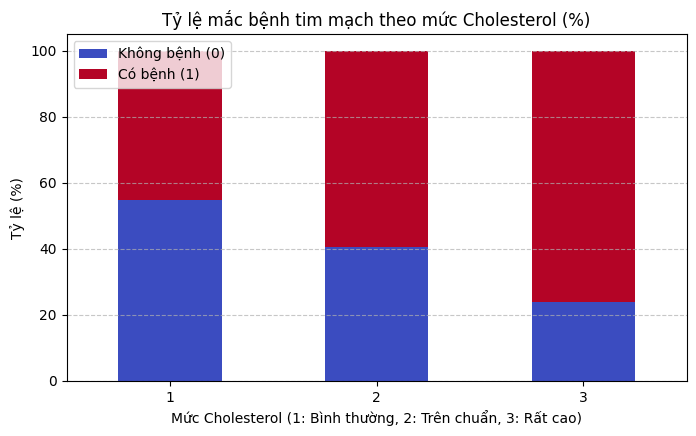

In [ ]:
# Phân tích tỷ lệ bệnh tim mạch theo mức Cholesterol

# pd.crosstab() tạo bảng chéo: hàng là mức cholesterol, cột là nhãn cardio
# normalize="index": mỗi hàng được chia sao cho tổng bằng 1
cholesterol_table = pd.crosstab(cardio_data["cholesterol"], cardio_data["cardio"], normalize="index")

# Nhân 100 để đổi sang phần trăm
cholesterol_percentage = cholesterol_table * 100

# kind="bar", stacked=True: vẽ biểu đồ cột chồng (mỗi cột cộng lại bằng 100%)
cholesterol_percentage.plot(kind="bar", stacked=True, figsize=(8, 4.5), colormap="coolwarm")
plt.title("Tỷ lệ mắc bệnh tim mạch theo mức Cholesterol (%)")
plt.xlabel("Mức Cholesterol (1: Bình thường, 2: Trên chuẩn, 3: Rất cao)")
plt.ylabel("Tỷ lệ (%)")

# rotation=0: giữ chữ trên trục X nằm ngang
plt.xticks(rotation=0)
plt.legend(["Không bệnh (0)", "Có bệnh (1)"], loc="upper left")

# Vẽ lưới ngang (axis="y"), nét đứt, độ mờ 0.7
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

**Các đặc điểm còn lại.** Biểu đồ này đếm số người. Khi hai nhóm có quy mô khác nhau, cần so sánh tỷ lệ trước khi kết luận nhóm nào thường mắc bệnh hơn.

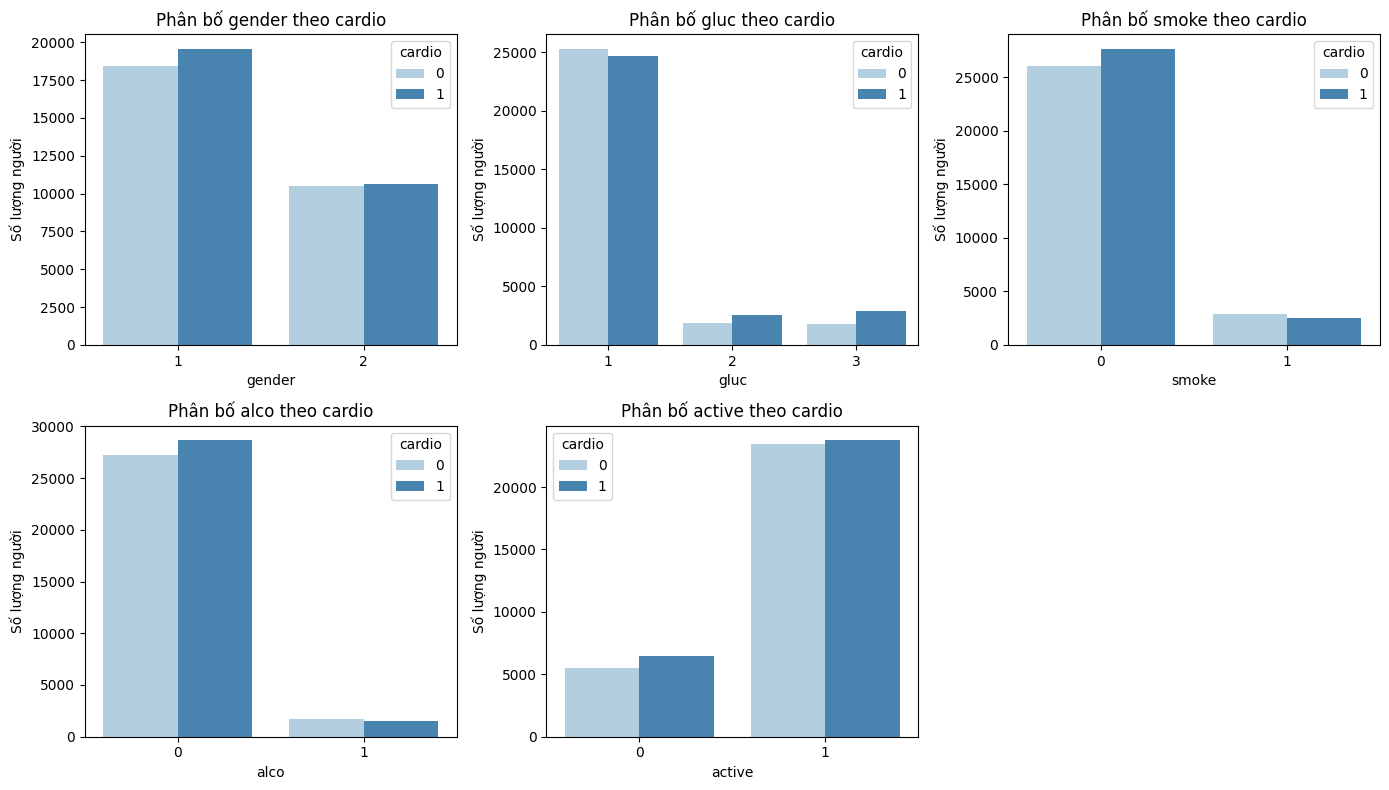

In [ ]:
# Phân bố các biến phân loại và thói quen sinh hoạt theo cardio
category_columns = ["gender", "gluc", "smoke", "alco", "active"]

# Tạo hình gồm 2 hàng x 3 cột = 6 ô biểu đồ
figure, axis_grid = plt.subplots(2, 3, figsize=(14, 8))
axis_list = axis_grid.flatten()

for position, column_name in enumerate(category_columns):
    current_axis = axis_list[position]

    # Đếm số người theo từng giá trị của cột, tách màu theo nhãn cardio
    sns.countplot(data=cardio_data, x=column_name, hue="cardio", ax=current_axis, palette="Blues")

    chart_title = "Phân bố " + column_name + " theo cardio"
    current_axis.set_title(chart_title)
    current_axis.set_xlabel(column_name)
    current_axis.set_ylabel("Số lượng người")

# Xóa ô thứ 6 bị thừa
figure.delaxes(axis_list[5])
plt.tight_layout()
plt.show()

#### 1.3. Chỉ số nào có tương quan với nhãn bệnh?

Hệ số dương cho biết hai biến có xu hướng tăng cùng nhau. Bỏ qua đường chéo vì mỗi biến được so với chính nó.

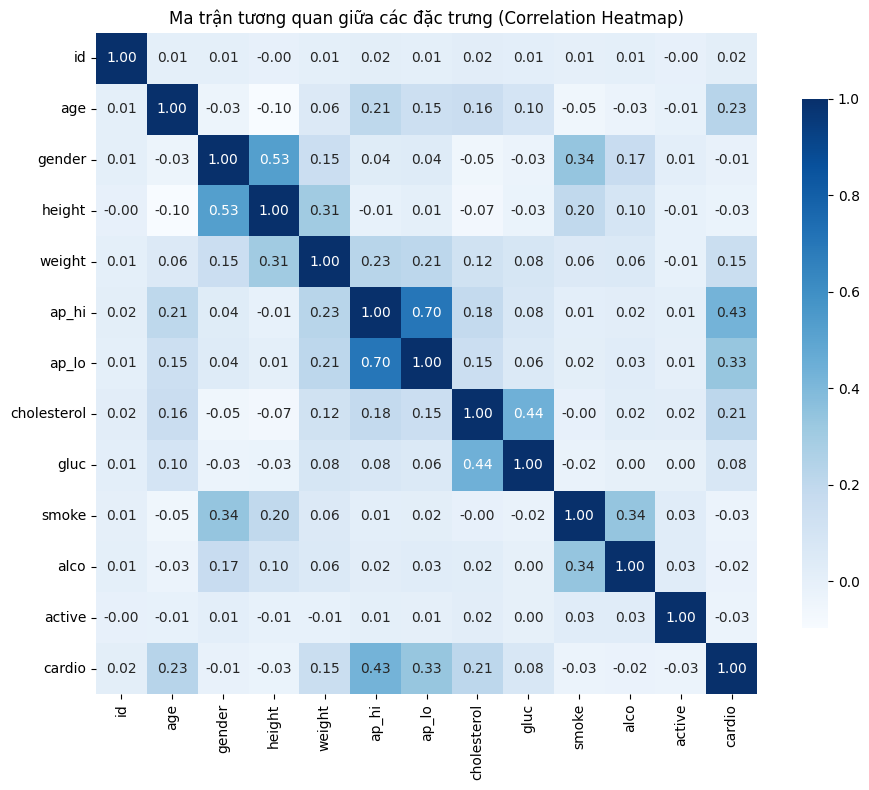

In [ ]:
# Tính ma trận tương quan giữa các biến số

# Bước 1: select_dtypes(include="number") chỉ giữ lại các cột kiểu số
numeric_data = cardio_data.select_dtypes(include="number")

# Bước 2: .corr() tính hệ số tương quan giữa từng cặp cột
correlation_matrix = numeric_data.corr()

# Vẽ Heatmap trực quan
plt.figure(figsize=(10, 8))

# annot=True: ghi số lên mỗi ô; fmt=".2f": hiện 2 chữ số thập phân
# square=True: ô hình vuông; cbar_kws={"shrink": 0.8}: thanh màu thu nhỏ còn 80%
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="Blues", square=True, cbar_kws={"shrink": 0.8})
plt.title("Ma trận tương quan giữa các đặc trưng (Correlation Heatmap)")
plt.tight_layout()
plt.show()

Đọc cột tương quan với `cardio`. Bỏ qua `id` vì đây chỉ là mã bản ghi.

In [ ]:
# Bảng hệ số tương quan sắp xếp giảm dần theo mức độ ảnh hưởng tới cardio
print("Hệ số tương quan tuyến tính với biến mục tiêu cardio (sắp xếp giảm dần):")

# Bước 1: lấy cột "cardio" trong ma trận tương quan
cardio_correlation = correlation_matrix["cardio"]

# Bước 2: sắp xếp giảm dần
cardio_correlation = cardio_correlation.sort_values(ascending=False)

# Bước 3: .to_frame() đổi từ Series (1 cột) sang DataFrame (bảng) để hiển thị đẹp hơn
cardio_correlation_table = cardio_correlation.to_frame()

# Đặt lại tên cột
cardio_correlation_table.columns = ["Correlation with cardio"]
display(cardio_correlation_table)

Hệ số tương quan tuyến tính với biến mục tiêu cardio (sắp xếp giảm dần):


,Correlation with cardio
cardio,1.000000
ap_hi,0.429393
ap_lo,0.334980
age,0.231734
cholesterol,0.209928
weight,0.154623
gluc,0.075915
id,0.018603
gender,-0.012395
alco,-0.019426


**Nhận xét từ kết quả đã lưu.** Huyết áp tâm thu (`ap_hi`, 0,43) và tâm trương (`ap_lo`, 0,34) có tương quan dương cao nhất với nhãn bệnh trong các chỉ số được xét. Đây là mối liên hệ quan sát được trong bộ dữ liệu.

# Phần 2. Chuẩn bị dữ liệu cho mô hình

#### 2.1. Chọn cột đầu vào và mã hóa

`X` chứa 11 đặc điểm sức khỏe và sinh hoạt. `y` chứa nhãn cần dự đoán. Cột `id` chỉ dùng để phân biệt các bản ghi.

In [ ]:
# Danh sách 11 đặc trưng độc lập được lựa chọn
feature_columns = [
    "age", "gender", "height", "weight", "ap_hi", "ap_lo",
    "cholesterol", "gluc", "smoke", "alco", "active"
]

# X: bảng các đặc trưng đầu vào (quy ước đặt tên phổ biến trong học máy)
# .copy() tạo bản sao để thay đổi X không ảnh hưởng đến cardio_data
X = cardio_data[feature_columns].copy()

# y: nhãn cần dự đoán
y = cardio_data["cardio"].copy()

`get_dummies` chuyển từng nhóm thành cột 0/1. Ví dụ, `cholesterol_3 = 1` nghĩa là người đó thuộc mức 3. Tham số `drop_first=True` giữ mức đầu làm nhóm đối chiếu.

In [ ]:
# One-Hot Encoding cho gender, cholesterol, gluc (drop_first=True để tránh đa cộng tuyến)
# pd.get_dummies() chuyển mỗi nhóm thành một cột 0/1
# dtype=int: các cột mới có giá trị số nguyên 0 hoặc 1
columns_to_encode = ["gender", "cholesterol", "gluc"]
X = pd.get_dummies(X, columns=columns_to_encode, drop_first=True, dtype=int)

print("Kích thước ma trận đặc trưng sau khi mã hóa:", X.shape)

encoded_column_names = X.columns.tolist()
print("Danh sách cột sau khi mã hóa:", encoded_column_names)
display(X.head())

Kích thước ma trận đặc trưng sau khi mã hóa: (59162, 13)
Danh sách cột sau khi mã hóa: ['age', 'height', 'weight', 'ap_hi', 'ap_lo', 'smoke', 'alco', 'active', 'gender_2', 'cholesterol_2', 'cholesterol_3', 'gluc_2', 'gluc_3']


,age,height,weight,ap_hi,ap_lo,smoke,alco,active,gender_2,cholesterol_2,cholesterol_3,gluc_2,gluc_3
0,50,168,62.0,110,80,0,0,1,1,0,0,0,0
1,55,156,85.0,140,90,0,0,1,0,0,1,0,0
2,52,165,64.0,130,70,0,0,0,0,0,1,0,0
3,48,169,82.0,150,100,0,0,1,1,0,0,0,0
4,60,151,67.0,120,80,0,0,0,0,1,0,1,0


#### 2.2. Chia dữ liệu thành hai tập

Dùng 80% để học và 20% để kiểm tra. `stratify=y` giúp hai tập có tỷ lệ người có bệnh gần nhau.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Phân chia 80% tập Train và 20% tập Test
# train_test_split() trả về 4 phần theo đúng thứ tự:
#   X_train (đặc trưng để học), X_test (đặc trưng để kiểm tra),
#   y_train (nhãn để học),      y_test (nhãn để kiểm tra)
# test_size=0.2: 20% cho tập kiểm tra
# random_state=42: cố định cách chia để lần chạy sau cho cùng kết quả
# stratify=y: giữ tỷ lệ nhãn 0/1 giống nhau ở cả hai tập
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

**Chuẩn hóa cho Logistic Regression.** Tính trung bình và độ lệch chuẩn trên tập huấn luyện, rồi dùng cùng các giá trị đó để biến đổi tập kiểm tra.

In [ ]:
# Chuẩn hóa dữ liệu với StandardScaler
# StandardScaler đưa mỗi cột về trung bình = 0 và độ lệch chuẩn = 1
standard_scaler = StandardScaler()

# fit_transform(): vừa tính trung bình, độ lệch chuẩn (fit) vừa biến đổi (transform)
# Chỉ fit trên tập Train để tránh rò rỉ dữ liệu (Data Leakage)
X_train_scaled = standard_scaler.fit_transform(X_train)

# transform(): biến đổi tập Test bằng trung bình và độ lệch chuẩn đã học từ Train
X_test_scaled = standard_scaler.transform(X_test)

**Kiểm tra lại** số hàng và tỷ lệ hai nhãn sau khi chia.

In [ ]:
print("Kích thước tập huấn luyện (X_train):", X_train.shape)
print("Số mẫu tập huấn luyện (Train):", len(y_train))
print("Kích thước tập kiểm tra (X_test):", X_test.shape)
print("Số mẫu tập kiểm tra (Test):", len(y_test))

# Tỷ lệ phần trăm mỗi nhãn trong tập Train
train_percentage = y_train.value_counts(normalize=True) * 100
train_percentage = train_percentage.round(2)

# .to_dict() đổi kết quả thành dictionary {nhãn: tỷ lệ} cho dễ đọc
print("Tỷ lệ phân bố cardio trong tập Train:\n", train_percentage.to_dict())

# Tỷ lệ phần trăm mỗi nhãn trong tập Test
test_percentage = y_test.value_counts(normalize=True) * 100
test_percentage = test_percentage.round(2)
print("Tỷ lệ phân bố cardio trong tập Test:\n", test_percentage.to_dict())

Kích thước tập huấn luyện (X_train): (47329, 13)
Số mẫu tập huấn luyện (Train): 47329
Kích thước tập kiểm tra (X_test): (11833, 13)
Số mẫu tập kiểm tra (Test): 11833
Tỷ lệ phân bố cardio trong tập Train:
 {1: 51.02, 0: 48.98}
Tỷ lệ phân bố cardio trong tập Test:
 {1: 51.03, 0: 48.97}


# Phần 3. Huấn luyện và đánh giá

#### 3.1. Khởi tạo ba mô hình

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Khởi tạo cấu hình 3 mô hình, lưu trong dictionary {tên mô hình: đối tượng mô hình}
# LogisticRegression: max_iter=1000 cho phép tối đa 1000 vòng lặp khi học
# DecisionTreeClassifier: max_depth=6 giới hạn cây sâu tối đa 6 tầng
# RandomForestClassifier: n_estimators=100 cây, mỗi cây sâu tối đa 10 tầng
# random_state=42: cố định kết quả để chạy lại vẫn giống nhau
models = {
    "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42),
}

**Huấn luyện và dự đoán.** Mỗi mô hình học trên cùng các hàng. `predict` trả về nhãn 0/1. `predict_proba` cho điểm xác suất thuộc nhóm 1 để tính ROC-AUC.

In [ ]:
# Danh sách lưu kết quả đánh giá của từng mô hình
results = []

# Dictionary lưu các mô hình đã huấn luyện: {tên mô hình: mô hình}
trained_models = {}

# Vòng lặp huấn luyện và đánh giá trên cùng tập Test
# models.items() trả về từng cặp (tên mô hình, đối tượng mô hình)
for model_name, model in models.items():

    # Logistic Regression là mô hình tuyến tính cần dữ liệu đã chuẩn hóa
    if model_name == "Logistic Regression":
        # fit(): cho mô hình học từ dữ liệu huấn luyện
        model.fit(X_train_scaled, y_train)

        # predict(): dự đoán nhãn 0/1 cho tập kiểm tra
        y_predicted = model.predict(X_test_scaled)

        # predict_proba(): trả về bảng 2 cột [xác suất nhãn 0, xác suất nhãn 1]
        # [:, 1] nghĩa là lấy tất cả các hàng, chỉ ở cột số 1 (xác suất có bệnh)
        probability_table = model.predict_proba(X_test_scaled)
        y_probability = probability_table[:, 1]
    else:
        # Các mô hình dựa trên cây (Tree-based) không bị ảnh hưởng bởi thang đo
        model.fit(X_train, y_train)
        y_predicted = model.predict(X_test)
        probability_table = model.predict_proba(X_test)
        y_probability = probability_table[:, 1]

    trained_models[model_name] = model

    # Tính từng chỉ số và làm tròn 3 chữ số thập phân
    accuracy_value = round(accuracy_score(y_test, y_predicted), 3)
    precision_value = round(precision_score(y_test, y_predicted), 3)
    recall_value = round(recall_score(y_test, y_predicted), 3)
    f1_value = round(f1_score(y_test, y_predicted), 3)
    # ROC-AUC dùng xác suất chứ không dùng nhãn 0/1
    roc_auc_value = round(roc_auc_score(y_test, y_probability), 3)

    # Gom kết quả của mô hình này vào một dictionary
    model_result = {
        "Model": model_name,
        "Accuracy": accuracy_value,
        "Precision": precision_value,
        "Recall": recall_value,
        "F1-score": f1_value,
        "ROC-AUC": roc_auc_value,
    }
    results.append(model_result)

**So sánh trên cùng tập kiểm tra.** Precision cho biết trong số người được dự đoán có bệnh, bao nhiêu người thực sự có bệnh. Recall cho biết mô hình tìm được bao nhiêu trong tổng số người có bệnh. F1 kết hợp hai chỉ số này.

In [ ]:
# Hiển thị bảng so sánh kết quả sắp xếp theo F1-score giảm dần

# pd.DataFrame() chuyển danh sách các dictionary thành bảng
results_table = pd.DataFrame(results)
results_table = results_table.sort_values("F1-score", ascending=False)

print("BẢNG TỔNG HỢP HIỆU NĂNG CÁC MÔ HÌNH TRÊN TẬP TEST:")
display(results_table)

# .iloc[0] lấy hàng đầu tiên của bảng (đã sắp xếp nên là mô hình F1 cao nhất)
best_row = results_table.iloc[0]
best_model_name = best_row["Model"]
best_model = trained_models[best_model_name]

print("\n--> Mô hình có F1-score cao nhất được lựa chọn: " + best_model_name)

BẢNG TỔNG HỢP HIỆU NĂNG CÁC MÔ HÌNH TRÊN TẬP TEST:


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
2,Random Forest,0.722,0.762,0.663,0.709,0.790
0,Logistic Regression,0.718,0.751,0.671,0.708,0.781
1,Decision Tree,0.721,0.759,0.664,0.708,0.781



--> Mô hình có F1-score cao nhất được lựa chọn: Random Forest


#### 3.2. Mô hình được chọn sai ở đâu?

Dùng mô hình đứng đầu bảng F1 ở bước 3.1. Trong ma trận, hàng là nhãn thật và cột là nhãn dự đoán. Ô hàng 1, cột 0 đếm số người có bệnh mà mô hình bỏ sót.

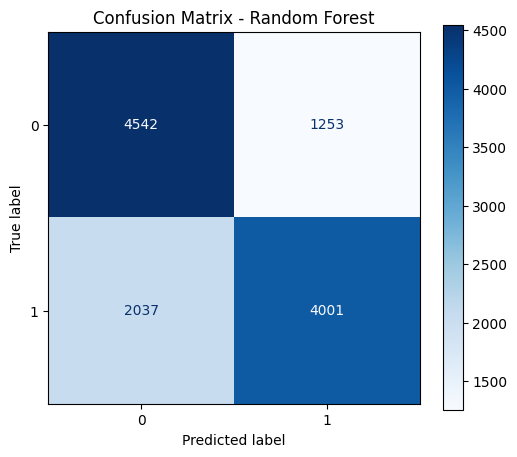

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

# Chọn đúng loại dữ liệu kiểm tra cho mô hình tốt nhất:
# Logistic Regression dùng dữ liệu đã chuẩn hóa, mô hình cây dùng dữ liệu gốc
X_test_best = X_test
if best_model_name == "Logistic Regression":
    X_test_best = X_test_scaled

# Vẽ Confusion Matrix
figure, axis = plt.subplots(figsize=(6, 5))

# from_estimator(): tự dự đoán trên X_test_best, so với y_test rồi vẽ ma trận
# cmap="Blues": tông màu xanh; values_format="d": hiện số nguyên
ConfusionMatrixDisplay.from_estimator(
    best_model, X_test_best, y_test, cmap='Blues', values_format='d', ax=axis
)
axis.set_title("Confusion Matrix - " + best_model_name)
axis.grid(False)
plt.show()

**Đọc đường ROC.** Khi thay đổi ngưỡng dự đoán, tỷ lệ phát hiện người có bệnh và tỷ lệ báo nhầm cùng thay đổi. Đường cong càng gần góc trên bên trái thì khả năng phân biệt hai nhóm càng tốt.

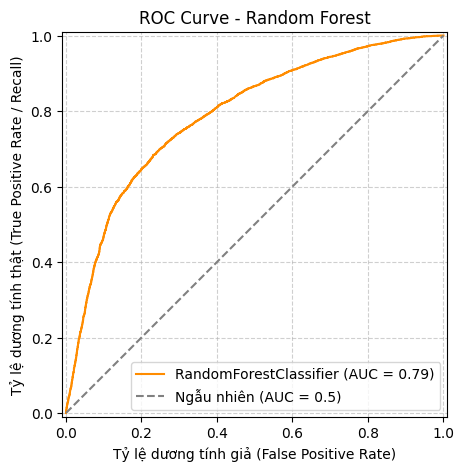

In [ ]:
figure, axis = plt.subplots(figsize=(6, 5))

# RocCurveDisplay.from_estimator() tự tính và vẽ đường ROC của mô hình
roc_display = RocCurveDisplay.from_estimator(best_model, X_test_best, y_test, ax=axis)

# .line_ là đường cong vừa vẽ; đổi màu thành cam đậm
roc_display.line_.set_color('darkorange')

# Đường chéo từ (0, 0) đến (1, 1) ứng với đoán ngẫu nhiên
axis.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Ngẫu nhiên (AUC = 0.5)')

axis.set_title("ROC Curve - " + best_model_name)
axis.set_xlabel('Tỷ lệ dương tính giả (False Positive Rate)')
axis.set_ylabel('Tỷ lệ dương tính thật (True Positive Rate / Recall)')
axis.legend(loc='lower right')
axis.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Phần 4. Kết luận

Trong lần chạy đã lưu, tập kiểm tra có **12.922 người**. Random Forest đạt F1 cao nhất (**0,720**), sát với Logistic Regression (**0,718**). Nếu ưu tiên phát hiện người có bệnh, Logistic Regression có Recall nhỉnh hơn (0,690 so với 0,686).

Với Recall 0,686, Random Forest phát hiện khoảng 69 trong mỗi 100 người có bệnh ở tập kiểm tra. Bước tiếp theo là thử các ngưỡng dự đoán trên tập xác thực và theo dõi số ca bỏ sót cùng số ca báo nhầm trước khi đánh giá trên dữ liệu mới.